# 02｜灰度、直方图和局部对比

目标：把一张真实金属表面照片转成灰度，观察亮度分布，再比较全局均衡和 CLAHE。灰度不是缺陷检测，只是把每个像素表示为一个亮度值。CLAHE 在小网格中增强对比，并限制过强放大，但仍可能增强噪声。

原理参考：[OpenCV 官方均衡教程](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html)。示例代码为本项目重新编写。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lab_utils.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


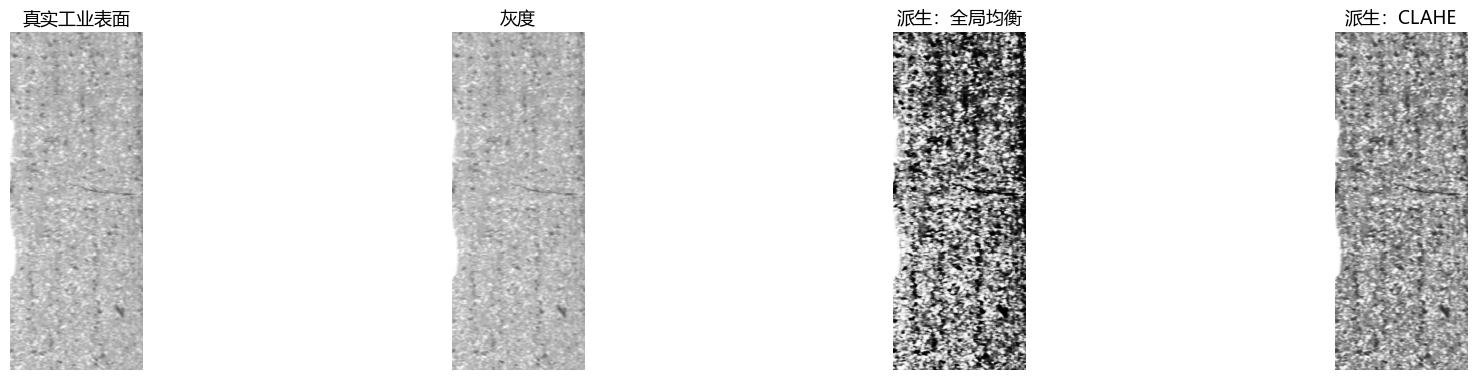

In [2]:
image = lab.load_case("kolektor_defect_0")
g = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
equalized = cv2.equalizeHist(g)
enhanced = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
lab.show_images([image, g, equalized, enhanced],
                ["真实工业表面", "灰度", "派生：全局均衡", "派生：CLAHE"], cols=4)

## 1. 直方图回答“有多少明暗像素”

横轴是灰度 0–255，纵轴是像素数量。直方图没有位置关系：裂纹在哪里、两块金属是否相邻都不能由它直接读出。峰值不等于某一种物体。

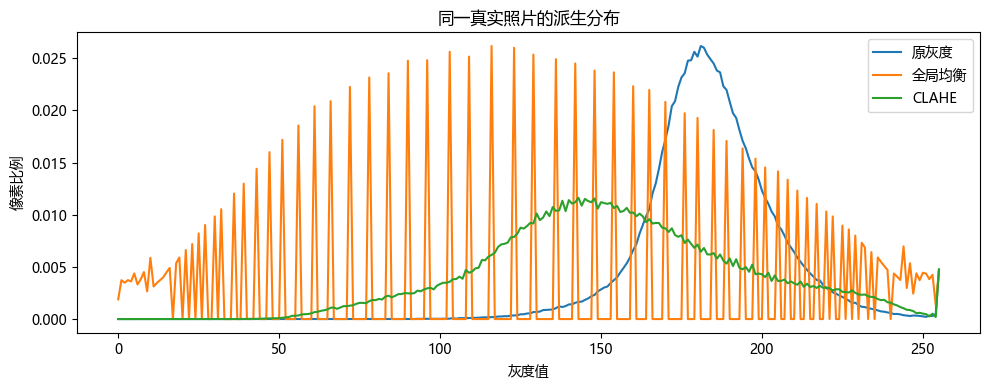

图像尺寸 (1270, 500) 类型 uint8 范围 82 255


In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for sample, name in [(g, "原灰度"), (equalized, "全局均衡"), (enhanced, "CLAHE")]:
    hist = cv2.calcHist([sample], [0], None, [256], [0, 256]).ravel()
    ax.plot(np.arange(256), hist / hist.sum(), label=name)
ax.set(xlabel="灰度值", ylabel="像素比例", title="同一真实照片的派生分布")
ax.legend(); fig.tight_layout(); plt.show(); plt.close(fig)
print("图像尺寸", g.shape, "类型", g.dtype, "范围", int(g.min()), int(g.max()))

## 2. 参数只改变效果，不创造真值

提高 `clipLimit` 可以更强地增强局部差异，也可能把噪声和正常加工纹理增强。观察下方三个值，并在原图上复核。不能因为处理后“看着有纹理”就判为焊好。

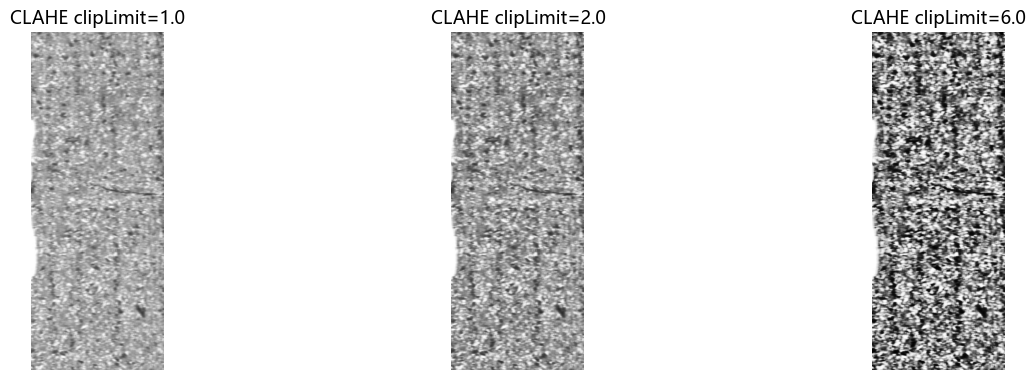


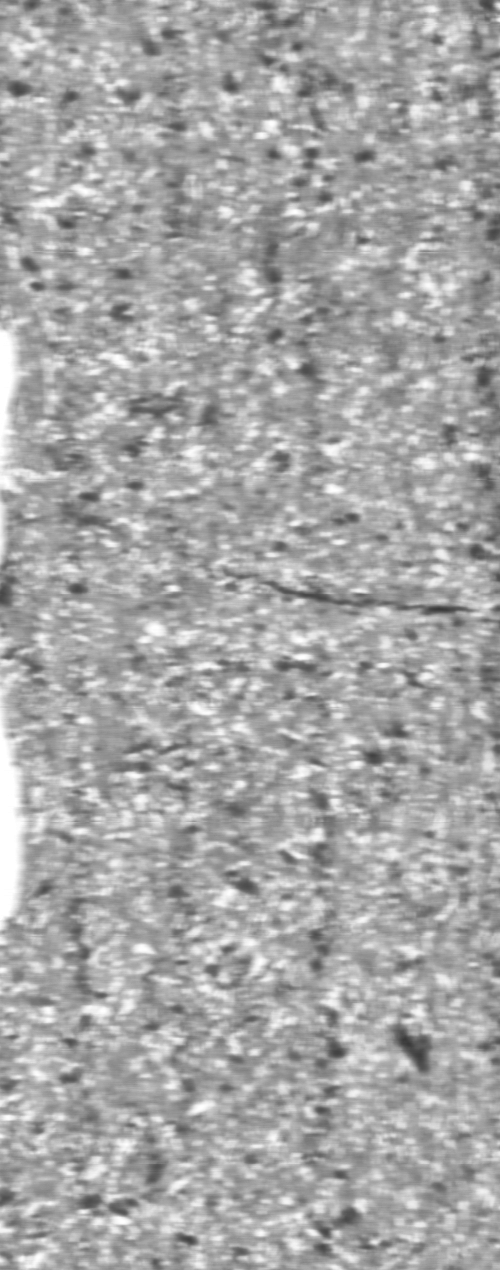
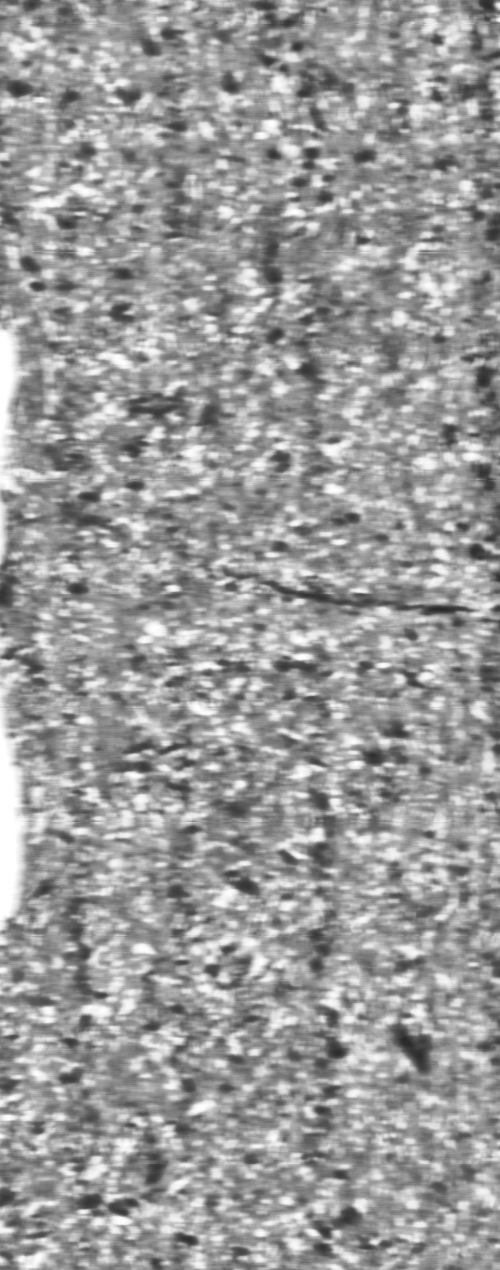
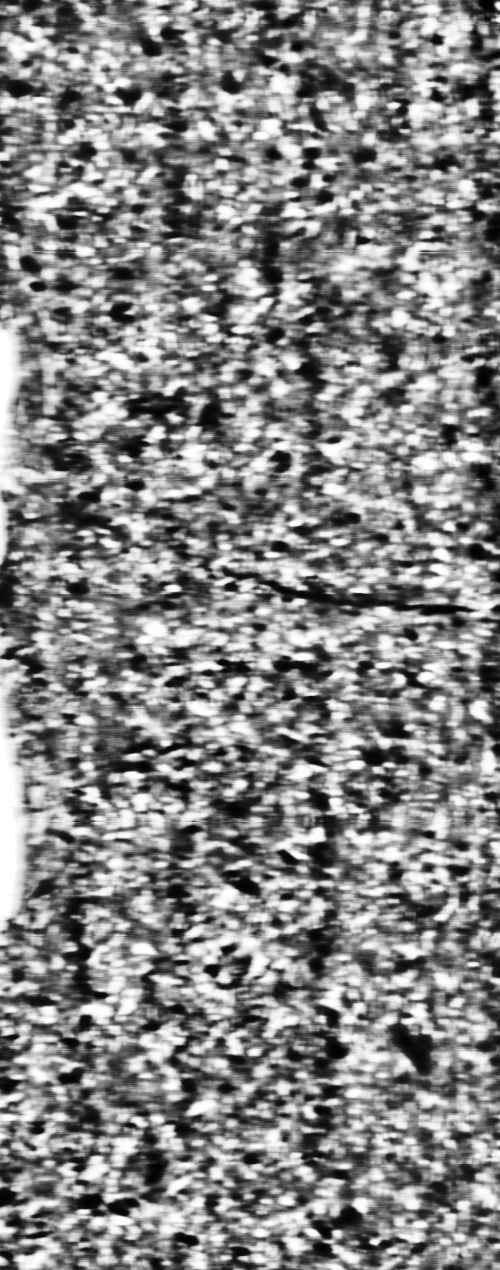
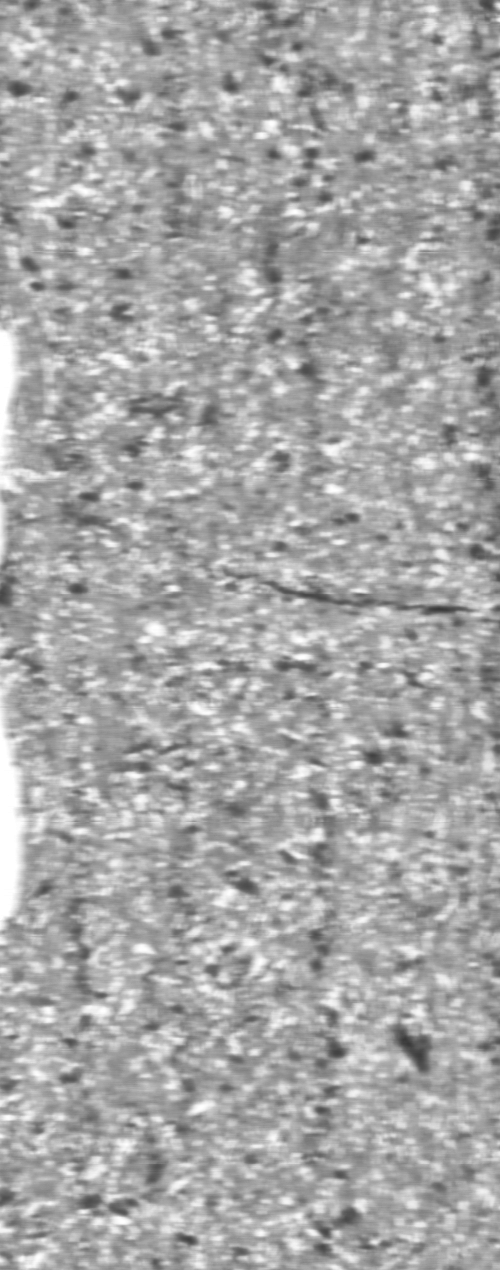

In [4]:
clips = [1.0, 2.0, 6.0]
alternatives = [cv2.createCLAHE(clipLimit=v, tileGridSize=(8, 8)).apply(g) for v in clips]
lab.show_images(alternatives, [f"CLAHE clipLimit={v}" for v in clips], cols=3)
display(HTML(lab.parameter_gallery(alternatives, [f"clipLimit={v}" for v in clips], "clahe")))
assert enhanced.shape == g.shape and enhanced.dtype == np.uint8

## 小练习

把案例改成 `kolektor_normal_0`，检查正常纹理是否同样被增强。再把 `tileGridSize` 从 `(8, 8)` 改为 `(4, 4)`，观察局部增强范围。记录参数和原文件摘要，避免日后无法重现。

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。